<center><h2><span style="font-weight:bolder; color:#6c757d; font-size:85%",>AirPlane Crashes Analysis & EDA</span></h2></center>

<center><h2><span style="font-weight:bolder; color:black; font-size:80%">Melissa Jalali Monfared</span></h2></center>

<a id="about"></a>
# <p style="background-color:#6c757d;font-family:newtimeroman;font-size:100%;color:black;text-align:center;border-radius:15px 50px; padding:7px;border: 1px solid black;">About Project & Dataset</p>

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">

<h3 align="left"><font color='#6c757d'>About Dataset:</font></h3>

The available dataset is about Airplane Crashes throughout the world since 1908.
    
|       **Name**  |**Define**|
|---------|------------|
|Date|Date of accident|
|Time|  Local time, in 24 hr. in the format hh:mm|
|Location|  Location of the accident|
|Operator | Airline or operator of the aircraft|
|Flight |Flight number assigned by the aircraft operator|
|Route | Complete or partial route flown prior to the accident|
|Type | Aircraft type|
|Registration| ICAO registration of the aircraft|
|cn/In | Construction or serial number / Line or fuselage number|
|Total Aboard| Total people aboard|
|Passengers Aboard|  Passengers aboard|
|Crew Aboard | Crew aboard |
|Total Fatalities | Total fatalities|
|Passengers Fatalities | Passengers fatalities|
|Crew Fatalities | Crew fatalities|
|Ground | Total killed on the ground|
|Summary | Brief description of the accident and cause if known|

<a id="pre"></a>
# <p style="background-color:#6c757d;font-family:newtimeroman;font-size:100%;color:black;text-align:center;border-radius:15px 50px; padding:7px;border: 1px solid black;">Preprocessing & Visualization</p>

In [1]:
import time
import nltk
import string
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from scipy import stats
from sklearn import metrics
import plotly.express as px
import statsmodels.api as sm
from itertools import product
from collections import Counter
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
import plotly.graph_objects as go
from statsmodels.formula.api import ols
from ydata_profiling import ProfileReport
from plotly.subplots import make_subplots
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings 
warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
data = pd.read_csv('/kaggle/input/airplane-crashes/Airplane_Crashes_and_Fatalities_Since_1908.csv')
df=data.copy()
df

,Date,Time,Location,Operator,Flight #,Route,Type,Registration,cn/In,Aboard,Fatalities,Ground,Summary
0,09/17/1908,17:18,"Fort Myer, Virginia",Military - U.S. Army,NaN,Demonstration,Wright Flyer III,NaN,1,2.0,1.0,0.0,"During a demonstration flight, a U.S. Army fly..."
1,07/12/1912,06:30,"AtlantiCity, New Jersey",Military - U.S. Navy,NaN,Test flight,Dirigible,NaN,NaN,5.0,5.0,0.0,First U.S. dirigible Akron exploded just offsh...
2,08/06/1913,NaN,"Victoria, British Columbia, Canada",Private,-,NaN,Curtiss seaplane,NaN,NaN,1.0,1.0,0.0,The first fatal airplane accident in Canada oc...
3,09/09/1913,18:30,Over the North Sea,Military - German Navy,NaN,NaN,Zeppelin L-1 (airship),NaN,NaN,20.0,14.0,0.0,The airship flew into a thunderstorm and encou...
4,10/17/1913,10:30,"Near Johannisthal, Germany",Military - German Navy,NaN,NaN,Zeppelin L-2 (airship),NaN,NaN,30.0,30.0,0.0,Hydrogen gas which was being vented was sucked...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5263,05/20/2009,06:30,"Near Madiun, Indonesia",Military - Indonesian Air Force,NaN,Jakarta - Maduin,Lockheed C-130 Hercules,A-1325,1982,112.0,98.0,2.0,"While on approach, the military transport cras..."
5264,05/26/2009,NaN,"Near Isiro, DemocratiRepubliCongo",Service Air,NaN,Goma - Isiro,Antonov An-26,9Q-CSA,5005,4.0,4.0,NaN,The cargo plane crashed while on approach to I...
5265,06/01/2009,00:15,"AtlantiOcean, 570 miles northeast of Natal, Br...",Air France,447,Rio de Janeiro - Paris,Airbus A330-203,F-GZCP,660,228.0,228.0,0.0,The Airbus went missing over the AtlantiOcean ...
5266,06/07/2009,08:30,"Near Port Hope Simpson, Newfoundland, Canada",Strait Air,NaN,Lourdes de BlanSablon - Port Hope Simpson,Britten-Norman BN-2A-27 Islander,C-FJJR,424,1.0,1.0,0.0,The air ambulance crashed into hills while att...


In [3]:
from ydata_profiling import ProfileReport
ProfileReport(df, minimal=True, progress_bar=False, samples=None, correlations=None, interactions=None, explorative=True, dark_mode=True, notebook={'iframe':{'height': '600px'}}, html={'style':{'primary_color': '#583101'}}, missing_diagrams={'heatmap': False, 'dendrogram': False}).to_notebook_iframe()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">

- Common Themes: Words like "plane," "flight," "crew," "takeoff," "engine," "land," "air," and "failure" are frequently mentioned, suggesting these are common elements or issues in the accident reports.
- Incident Phases: References to different flight phases, such as "takeoff" and "approach," indicate that incidents often occur during these critical moments.
- Environmental Factors: Words like "weather," "mountain," and "ground" emphasize environmental factors that may contribute to aviation incidents.
- Types of Incidents: Terms like "crash," "fire," and "collision" describe the nature of some incidents.
Technical Issues: "Engine" and "failure" suggest that technical malfunctions or failures are a significant factor in the reports.
- Human Factors: The presence of words like "crew," "captain," and "pilot error" indicates that human factors are also frequently mentioned in the context of these incidents.
    
Word clouds like this one can be used to quickly identify the most common factors associated with aviation incidents and can guide further analysis or highlight areas for improvement in aviation safety. 

In [4]:
df.columns

Index(['Date', 'Time', 'Location', 'Operator', 'Flight #', 'Route', 'Type',
       'Registration', 'cn/In', 'Aboard', 'Fatalities', 'Ground', 'Summary'],
      dtype='object')

In [5]:
df.shape

(5268, 13)

In [6]:
def check_df(df: object, head: object = 5) -> object:
    print("\nShape")
    print(df.shape)
    print("\nTypes")
    print(df.dtypes)
    print("\nNANs")
    print(df.isnull().sum())
    print("\nInfo")
    print(df.info())
check_df(df)


Shape
(5268, 13)

Types
Date             object
Time             object
Location         object
Operator         object
Flight #         object
Route            object
Type             object
Registration     object
cn/In            object
Aboard          float64
Fatalities      float64
Ground          float64
Summary          object
dtype: object

NANs
Date               0
Time            2219
Location          20
Operator          18
Flight #        4199
Route           1707
Type              27
Registration     335
cn/In           1228
Aboard            22
Fatalities        12
Ground            22
Summary          390
dtype: int64

Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5268 entries, 0 to 5267
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          5268 non-null   object 
 1   Time          3049 non-null   object 
 2   Location      5248 non-null   object 
 3   Operator      5250 non-n

In [7]:
print('Object Columns:')
for count,column_name in enumerate(df.select_dtypes(include=['object']).columns,1):
    print(f'\t\t\t\t{count}) {column_name}')

Object Columns:
				1) Date
				2) Time
				3) Location
				4) Operator
				5) Flight #
				6) Route
				7) Type
				8) Registration
				9) cn/In
				10) Summary


In [8]:
print('Floating Columns:') 
for count,column_name in enumerate(df.select_dtypes(include=['float']).columns,1):
    print(f'\t\t\t\t{count}) {column_name}')

Floating Columns:
				1) Aboard
				2) Fatalities
				3) Ground


In [9]:
print('Number of duplicated rows: ' , len(df[df.duplicated()]))

Number of duplicated rows:  0


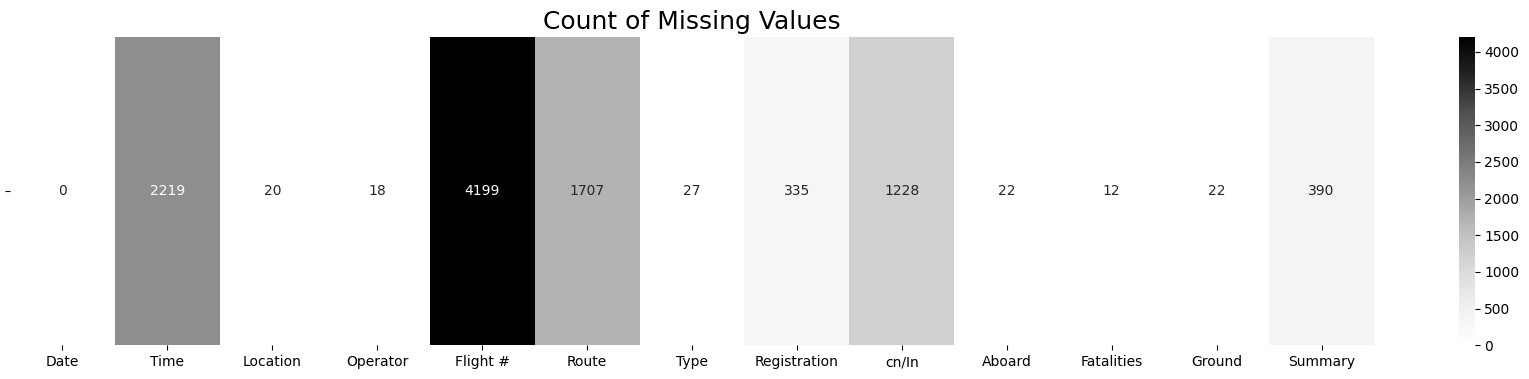

In [10]:
plt.figure(figsize=(22,4))
sns.heatmap((df.isna().sum()).to_frame(name='').T,cmap='Greys', annot=True,
             fmt='0.0f').set_title('Count of Missing Values', fontsize=18)
plt.show()

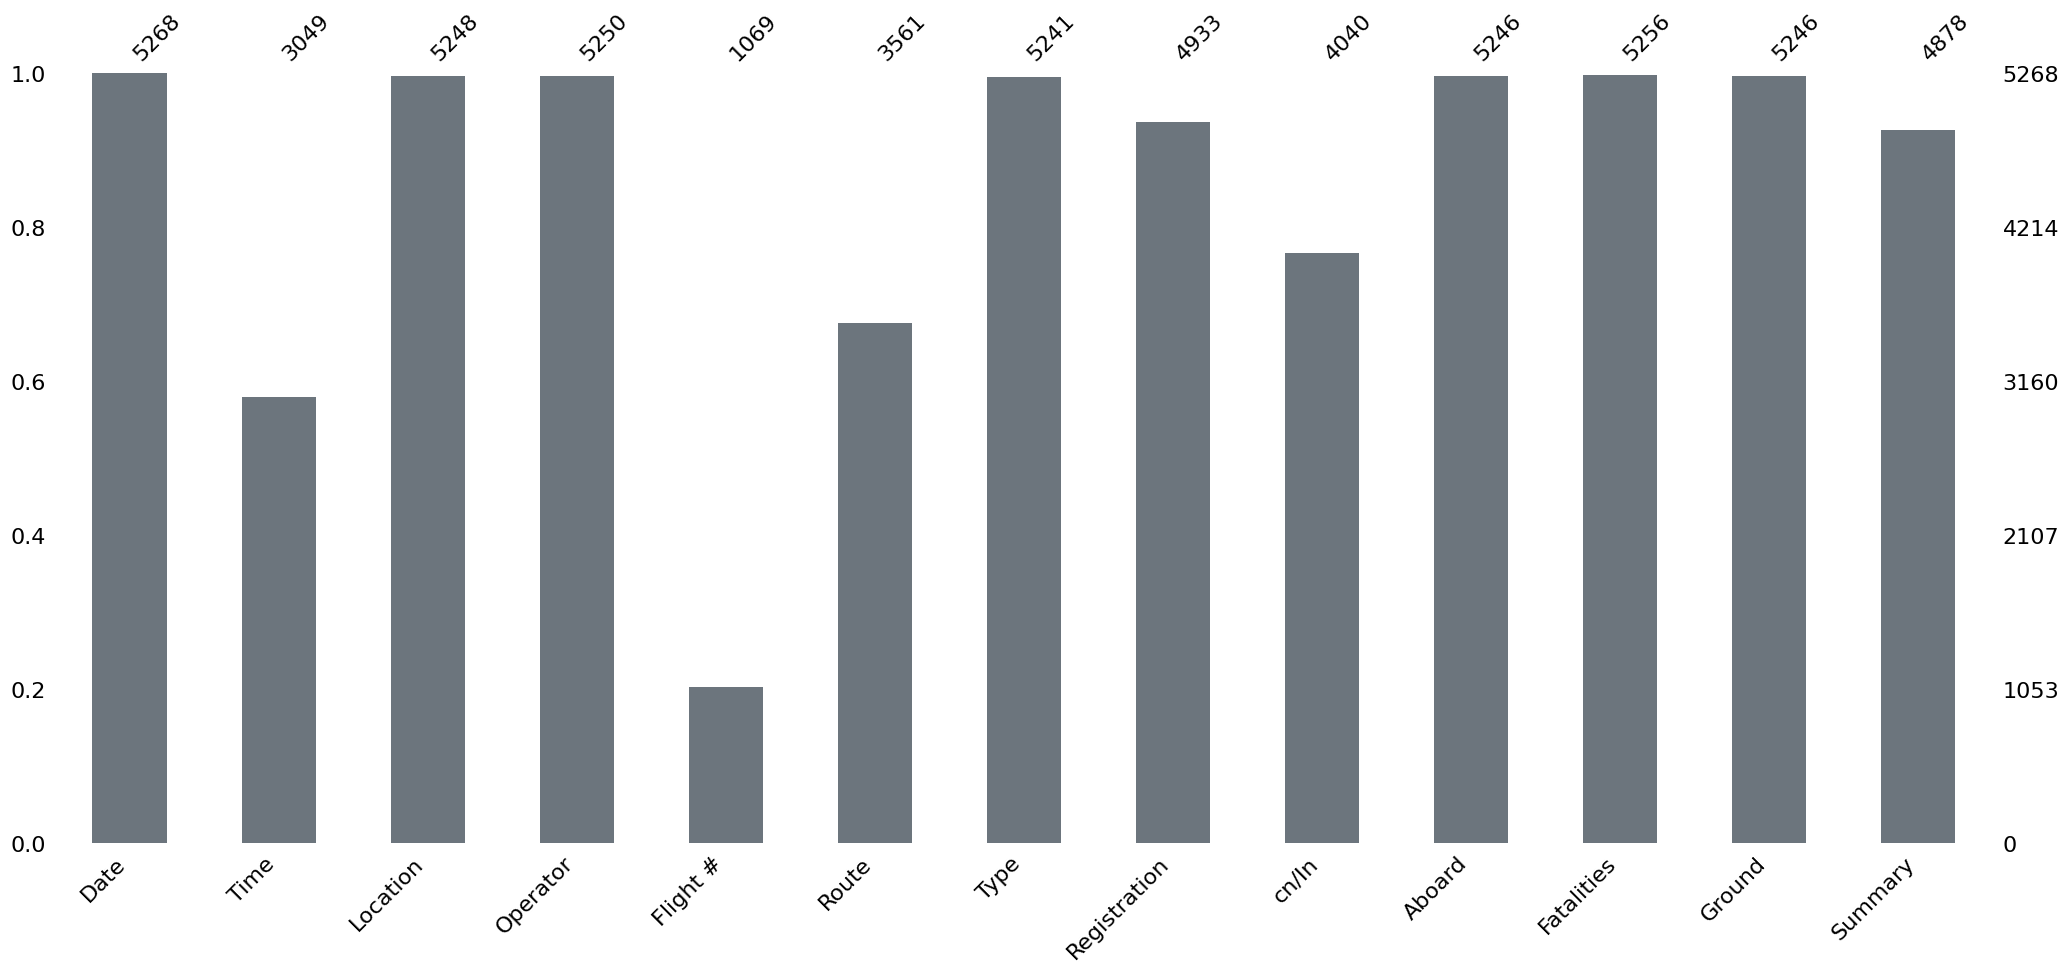

In [11]:
import missingno as msno
msno.bar(df, color='#6c757d')
plt.show()

In [12]:
missing=df.isna().sum()

In [13]:
custom_palette = ['#343a40', '#495057', '#6c757d', '#adb5bd', '#ced4da']
percentage = missing/len(df)*100
percentage.round(2)
threshold =  7.40
per = percentage[percentage>threshold]
fig = px.pie(values=per,names=per.index,color_discrete_sequence=custom_palette)
fig.update_layout(
    title={'text': 'Percentage of top 5 missing values','font': {'size': 20}
           },paper_bgcolor = 'white')

fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">

- There are no duplicated rows.
- NaN datas:
    
    - Flight        4199
    - Time            2219
    - Route           1707
    - cn/In           1228
    - Summary          390
    - Registration     335
    - Type              27
    - Aboard            22
    - Ground            22
    - Location          20
    - Operator          18
    - Fatalities        12

In [14]:
df.describe()[1:].T.style.background_gradient(cmap='Greys', axis=1)

,mean,std,min,25%,50%,75%,max
Aboard,27.554518,43.076711,0.000000,5.000000,13.000000,30.000000,644.000000
Fatalities,20.068303,33.199952,0.000000,3.000000,9.000000,23.000000,583.000000
Ground,1.608845,53.987827,0.000000,0.000000,0.000000,0.000000,2750.000000


In [15]:
df.select_dtypes(include=['object']).describe().T

,count,unique,top,freq
Date,5268,4753,09/11/2001,4
Time,3049,1005,15:00,32
Location,5248,4303,"Sao Paulo, Brazil",15
Operator,5250,2476,Aeroflot,179
Flight #,1069,724,-,67
Route,3561,3243,Training,81
Type,5241,2446,Douglas DC-3,334
Registration,4933,4905,49,3
cn/In,4040,3707,178,6
Summary,4878,4673,Crashed during takeoff.,15


<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">
    
- We can see statistical information on the table above.

In [16]:
# finding unique data
df.apply(lambda x: len(x.unique()))

Date            4753
Time            1006
Location        4304
Operator        2477
Flight #         725
Route           3244
Type            2447
Registration    4906
cn/In           3708
Aboard           240
Fatalities       192
Ground            51
Summary         4674
dtype: int64

In [17]:
unique = df.nunique().sort_values()
unique_values = df.apply(lambda x: x.unique())
pd.DataFrame({'Number of Unique Values': unique, 'Unique Values': unique_values})

,Number of Unique Values,Unique Values
Aboard,239,"[2.0, 5.0, 1.0, 20.0, 30.0, 41.0, 19.0, 22.0, ..."
Date,4753,"[09/17/1908, 07/12/1912, 08/06/1913, 09/09/191..."
Fatalities,191,"[1.0, 5.0, 14.0, 30.0, 21.0, 19.0, 20.0, 22.0,..."
Flight #,724,"[nan, -, 7, 599, 6, 4, 1, 14, 34, 23, 15A, LZ ..."
Ground,50,"[0.0, nan, 1.0, 5.0, 11.0, 2.0, 52.0, 22.0, 20..."
Location,4303,"[Fort Myer, Virginia, AtlantiCity, New Jersey,..."
Operator,2476,"[Military - U.S. Army, Military - U.S. Navy, P..."
Registration,4905,"[nan, 97, 61, 82, 32, G-EAHG, 77, 65, 72, 49, ..."
Route,3243,"[Demonstration, Test flight, nan, Varsovie - S..."
Summary,4673,"[During a demonstration flight, a U.S. Army fl..."


In [18]:
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = pd.DatetimeIndex(df['Date']).month
df['Year'] = pd.DatetimeIndex(df['Date']).year

In [19]:
# split the company name
df['Manufacture'] = df['Type'].apply(lambda x: x.split(' ')[0] if type(x) == str else 'Others')

In [20]:
# handle null values
warnings.filterwarnings("ignore")
df['Location'].fillna('', inplace=True)
df['Flight #'].fillna('Unavailable', inplace=True)
df['Route'].fillna('Unavailable', inplace=True)
df['Place'] = df['Location'].apply(lambda x: x.split(',')[0] if ',' in x else x)
df['Time'].fillna('Unknown',inplace=True)
df['Time'].isnull().any()
df['Operator'].fillna(df['Operator'].mode()[0],inplace = True)
df['cn/In'].fillna('Unknown', inplace=True)
df['Registration'].fillna(df['Registration'].mode()[0],inplace=True)
df['Type'].fillna(df['Type'].mode()[0],inplace=True)
df['Aboard'].fillna(df['Aboard'].mean(),inplace=True)
df['Fatalities'].fillna(df['Fatalities'].mean(),inplace=True)
df['Ground'].fillna(df['Ground'].mean(),inplace=True)
df['Summary'].fillna('Unknown',inplace=True)
warnings.resetwarnings()

In [21]:
df.describe()[1:].T.style.background_gradient(cmap='Greys', axis=1)

,mean,min,25%,50%,75%,max,std
Date,1971-10-23 15:50:42.369020480,1908-09-17 00:00:00,1954-04-11 18:00:00,1973-03-04 00:00:00,1990-06-26 18:00:00,2009-06-08 00:00:00,nan
Aboard,27.554518,0.000000,5.000000,13.000000,30.000000,644.000000,42.986652
Fatalities,20.068303,0.000000,3.000000,9.000000,23.000000,583.000000,33.162110
Ground,1.608845,0.000000,0.000000,0.000000,0.000000,2750.000000,53.874957
Month,6.643888,1.000000,3.000000,7.000000,10.000000,12.000000,3.546162
Year,1971.300304,1908.000000,1954.000000,1973.000000,1990.000000,2009.000000,22.387541


In [22]:
numerical_columns = df.select_dtypes(include=[int,float]).columns
descibe_numerical = df[numerical_columns].describe()
categorical_columns = ['Operator','Type','Manufacture']
frequency_counts = df[categorical_columns].value_counts()
modes = df[categorical_columns].mode() 
print('summary statistics')
print(descibe_numerical)
print('\nFrequency Counts')
print(frequency_counts.head(20))
print('\n\n Modes')
print(modes) 

summary statistics
            Aboard   Fatalities       Ground        Month         Year
count  5268.000000  5268.000000  5268.000000  5268.000000  5268.000000
mean     27.554518    20.068303     1.608845     6.643888  1971.300304
std      42.986652    33.162110    53.874957     3.546162    22.387541
min       0.000000     0.000000     0.000000     1.000000  1908.000000
25%       5.000000     3.000000     0.000000     3.000000  1954.000000
50%      13.000000     9.000000     0.000000     7.000000  1973.000000
75%      30.000000    23.000000     0.000000    10.000000  1990.000000
max     644.000000   583.000000  2750.000000    12.000000  2009.000000

Frequency Counts
Operator                             Type                      Manufacture
US Aerial Mail Service               De Havilland DH-4         De             26
Aeroflot                             Yakovlev YAK-40           Yakovlev       19
Deutsche Lufthansa                   Junkers JU-52/3m          Junkers        16
Milita

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">
    

- Aboard and Fatalities: On average, there were about 27 people on a crashed flight with around 20 fatalities. In some cases, there were as many as 644 people aboard and 583 fatalities.
- Ground: On average, about 1.6 ground fatalities were reported. One incident had an unusually high 2,750 ground fatalities.
- Month and Year: The crashes in the dataset occurred between 1908 and 2009, with June being the average month of crashes. The dataset's range of years allows for potential analysis of crash trends over time.
- Operator, Type, and Manufacturer: The dataset provides insights into the most common operators, aircraft types, and manufacturers involved in crashes. For example, the "US Aerial Mail Service" had the most occurrences with 26, while the "De Havilland DH-4" manufactured by "De" also had 26 occurrences. These insights can help identify patterns or focus further analysis on specific operators, types, or manufacturers.

In [23]:
accidents_by_location = df['Location'].value_counts().reset_index()
accidents_by_location.columns=['Location','Accident Count']
top_20_locations = accidents_by_location.head(20)
print(top_20_locations)

                     Location  Accident Count
0                                          20
1           Sao Paulo, Brazil              15
2              Moscow, Russia              15
3      Rio de Janeiro, Brazil              14
4            Bogota, Colombia              13
5           Anchorage, Alaska              13
6         Manila, Philippines              13
7          New York, New York              12
8                Cairo, Egypt              12
9           Chicago, Illinois              11
10        Near Moscow, Russia               9
11               Tehran, Iran               9
12               AtlantiOcean               9
13              Paris, France               8
14           Denver, Colorado               8
15                Rome, Italy               8
16             Ankara, Turkey               8
17     Amsterdam, Netherlands               8
18             Kunming, China               7
19  Guatemala City, Guatemala               7


In [24]:
accident_types_by_location = df.groupby('Location')['Type'].apply(lambda x: x.value_counts().idxmax()).reset_index()
accident_types_by_location.columns = ['Location','Most Common Accident Type']
accident_types_by_location = accident_types_by_location.head(10)
accident_types_by_location

,Location,Most Common Accident Type
0,,Junkers JU-53/3m
1,"1,200 miles off Dakar, AtlantiOcean",Latecoere 631 (flying boat)
2,"100 miles SW of Kuujjuaq, Quebec, Canada",Cessna 180K
3,"110 miles SW of Sochi, Russia",Tupolev Tu-154M
4,"200 miles NE of Derby, Australia",Robertson R44 helicopter
5,"25 nm off Agrigento, Italy",Vickers Valetta Mk1 / Avero Lancaster
6,"300 nm NW of San Francisco, California",Boeing B-747-SP-09
7,"900 miles E of Honolulu, Hawaii, PacifiOcean",Boeing - 377-10-29 Stratocruiser
8,"950 nm S of Shemya, Alaska",McDonnell Douglas MD-11
9,"Abakan, Siberia, Russia",Ilyushin IL-76MD


In [25]:
accidents_byy_location = df['Location'].value_counts().reset_index()
accidents_byy_location.columns=['Location','Accident Count']
top_locations = accidents_byy_location.head(5268)

In [26]:
warnings.filterwarnings("ignore")
fig = px.choropleth(top_locations, locations='Location', locationmode = "country names", hover_name='Location'
                   ,color_continuous_scale="Gray",color='Accident Count',projection='van der grinten', title='Accident Count By Location')
fig.show()

In [27]:
accidents_byyy_location = df['Location'].value_counts().reset_index()
accidents_byyy_location.columns=['Location','Accident Count']
top = accidents_byyy_location.head(30)

In [28]:
warnings.filterwarnings("ignore")
data = top_20_locations[['Location', 'Accident Count']].sort_values('Accident Count', ascending=False)[:20]
colors = ['#212529', '#343a40', '#495057', '#6C757D', '#ADB5BD', '#CED4DA', '#DEE2E6', '#E9ECEF', '#E9ECEF', '#F8F9FA', '#E9ECEF', '#DEE2E6','#CED4DA','#ADB5BD','#6C757D','#495057','#343a40','#212529','#161a1d','#0b090a']
fig = go.Figure(go.Bar(
            x=data['Accident Count'][::-1],
            y=data['Location'][::-1],
            marker=dict(color=colors),
            text=data['Accident Count'].apply(lambda x:str(int(x)))[::-1], 
            textposition='outside',
            orientation='h'))
fig.update_layout(
    title='Top Locations With the highest Accident Count',
    xaxis_title="inflation Size",
    template='gridon',
    plot_bgcolor='rgba(0, 0, 0, 0)',
    paper_bgcolor='rgba(0, 0, 0, 0)',)
fig.show()
df_sorted = top.sort_values('Accident Count', ascending=False)
top_n = 30
top_countries = df_sorted.head(top_n)
other_inflation = df_sorted.iloc[top_n:]['Accident Count'].sum()
new_df = pd.concat([top_countries, pd.DataFrame({'Location': ['Others'], 'Accident Count': [other_inflation]})])
colors = ['#212529', '#343a40', '#495057', '#6C757D', '#ADB5BD', '#CED4DA', '#DEE2E6', '#E9ECEF', '#E9ECEF', '#F8F9FA', '#E9ECEF', '#DEE2E6','#CED4DA','#ADB5BD','#6C757D','#495057','#343a40','#212529','#161a1d','#0b090a','#212529', '#343a40', '#495057', '#6C757D', '#ADB5BD', '#CED4DA', '#DEE2E6', '#E9ECEF', '#E9ECEF', '#F8F9FA']
fig = go.Figure(data=[go.Pie(labels=new_df['Location'],
                             values=new_df['Accident Count'],
                             textinfo="label+percent",
                             pull=[0, 0, 0],
                             showlegend=False,
                             marker_colors=colors,
                            )])
fig.update_traces(
    hole=0.6)
fig.update_layout(
    template='gridon',
    plot_bgcolor='rgba(0, 0, 0, 0)',
    paper_bgcolor='rgba(0, 0, 0, 0)',
)
fig.show()

In [29]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.bar(accident_types_by_location, x='Location', y='Most Common Accident Type',template = 'plotly_white')
fig.update_traces(marker_color='#6c757d')
fig.update_layout(title='Most Common Accident Type by Location',title_x = 0.5)
fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">
    
- Accident Counts by Location:
In Moscow, Russia & Sao Paulo, Brazil there are the most accidents, totaling 15+15=30. Following them, the next highest accident counts are in Rio de Janeiro, Brazil (14 accidents).

- Most Common Accident Types by Location:
The location "1,200 miles off Dakar, AtlantiOcean" experiences the most common accident type: "Latecoere 631 (flying boat)". Similarly, other locations like "100 miles SW of Kuujjuaq, Quebec, Canada", "110 miles SW of Sochi, Russia", "200 miles NE of Derby, Australia", and "25 nm off Agrigento, Italy" have their respective most common accident types.

- Geographic Distribution:
Accidents span across various countries and regions, including Russia, Brazil, the Philippines, Alaska, Colombia, Egypt, Iran, and more. Reported accidents occur in major cities like Moscow, Sao Paulo, Rio de Janeiro, Manila, New York, Chicago, and Tehran, as well as remote areas or specific coordinates like "1,200 miles off Dakar, AtlantiOcean" and "100 miles SW of Kuujjuaq, Quebec, Canada".

- Varying Accident Counts:
The number of accidents varies significantly among different locations, ranging from 9 accidents in Tehran, Iran, to 15 accidents in Moscow, Russia. There are relatively high accident counts in both urban areas (e.g., Moscow, Sao Paulo) and remote or specific locations (e.g., "1,200 miles off Dakar, AtlantiOcean", "110 miles SW of Sochi, Russia").

In [30]:
operator_counts = df['Operator'].value_counts().reset_index().head(25)
operator_counts.columns = ['Operator','Accident Count']
operator_counts

,Operator,Accident Count
0,Aeroflot,197
1,Military - U.S. Air Force,176
2,Air France,70
3,Deutsche Lufthansa,65
4,China National Aviation Corporation,44
5,Air Taxi,44
6,United Air Lines,44
7,Military - U.S. Army Air Forces,43
8,Pan American World Airways,41
9,Military - U.S. Navy,36


In [31]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
operator_counts['Accident Count'] = operator_counts['Accident Count'].astype('int')
fig = px.bar(operator_counts,x='Operator', y='Accident Count',template = 'plotly_white')
fig.update_traces(marker_color='#6c757d')
fig.update_layout(title = 'Top 25 Operators With The Most Accidents',title_x=0.5)
print(fig.show())

None


<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">

- Here are some key takeaways: 
    - Aeroflot has the highest number of accidents, with 197 occurrences. 
    - The U.S. Air Force (Military) follows closely behind with 176 accidents. 
    - Air France, Deutsche Lufthansa, and China National Aviation Corporation have relatively high accident counts, with 70, 65, and 44 accidents respectively. 
    - Air Taxi, United Air Lines, and the U.S. Army Air Forces (Military) share the same number of accidents, each with 44 occurrences. 
    - Pan American World Airways and the U.S. Navy (Military) complete the top 10 list with 41 and 36 accidents respectively. 

    
- Route Analysis: Investigate if specific routes are more prone to accidents or if certain types of accidents occur more frequently on particular routes.

- Aircraft Type Analysis: Understand if there are any associations between specific aircraft types, registration numbers, and manufacturers with accident occurrences or severity.

- Relationship between Aboard, Fatalities, and Ground: Calculate the fatality rate by dividing the number of fatalities by the number of people aboard the aircraft. Explore correlations between the number of people on board and the number of fatalities or ground casualties.

- Summary Analysis: Identify common factors or causes mentioned in accident descriptions using text analysis techniques such as word frequency or sentiment analysis.

In [32]:
aircraft = df.groupby(['Type','Registration','Manufacture']).size().reset_index()
aircraft.columns = ['Aircraft Type','Registration','Manufacture','Accidents']
aircraft = aircraft.sort_values(by='Accidents',ascending=False)
aircraft.reset_index(inplace=True)
aircraft=aircraft.head(25)
aircraft

,index,Aircraft Type,Registration,Manufacture,Accidents
0,2251,Douglas DC-3,49,Others,17
1,1902,Douglas C-47,49,Douglas,16
2,228,Antonov AN-26,49,Antonov,13
3,2250,Douglas DC-3,49,Douglas,12
4,1021,Breguet 14,49,Breguet,9
5,135,Antonov AN-12,49,Antonov,9
6,4150,Mil Mi-8 (helicopter),49,Mil,8
7,1669,Curtiss C-46,49,Curtiss,6
8,2830,Douglas M-4,49,Douglas,5
9,4354,Pitcairn PA-6 Mailwing,49,Pitcairn,4


In [33]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.bar(aircraft,x='Aircraft Type',y='Accidents',title='Top 25 Aircraft Types By Accidents',template = 'plotly_white')
fig.update_traces(marker_color='#6c757d')
fig.update_layout(title_x = 0.5)
fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">

- Types of Aircraft: The most frequent aircraft involved in accidents are the Douglas DC-3, Douglas C-47, and Antonov AN-26. These types have had the most accidents.

- Makers: The companies linked to the top aircraft types are Others, Douglas, Antonov, Mil, Curtiss, and Pitcairn. There's a mix of manufacturers involved, showing a wide range associated with the accidents.

- Accident Frequency: The "Accident Occurrences" column shows how often each combination of aircraft type, registration, and manufacturer appears in the data. The most common combo, Douglas DC-3 with registration number 49 and linked to the manufacturer Others, has happened 17 times.

In [34]:
fatality = df['Aboard'].corr(df['Fatalities'])
ground = df['Aboard'].corr(df['Ground'])
print('Correlation betwwen Aboard and Fatalities:', fatality)
print('Correlation between Aboard and Aboard:', ground)

Correlation betwwen Aboard and Fatalities: 0.7567135098438178
Correlation between Aboard and Aboard: 0.023236441300522485


<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">

The correlation between the number of people aboard and the number of fatalities is 0.757, showing a moderately strong positive correlation. This means that as the number of people on the aircraft increases, so does the number of fatalities. 📈

Conversely, the correlation between the number of people aboard and the number of ground casualties is 0.023, indicating a very weak positive correlation. This suggests little to no relationship between the number of people aboard the aircraft and the number of ground casualties.

      Aboard  Fatalities    Ground
0        2.0         1.0  0.000000
1        5.0         5.0  0.000000
2        1.0         1.0  0.000000
3       20.0        14.0  0.000000
4       30.0        30.0  0.000000
...      ...         ...       ...
5263   112.0        98.0  2.000000
5264     4.0         4.0  1.608845
5265   228.0       228.0  0.000000
5266     1.0         1.0  0.000000
5267    13.0        13.0  0.000000

[5268 rows x 3 columns]


<function matplotlib.pyplot.show(close=None, block=None)>

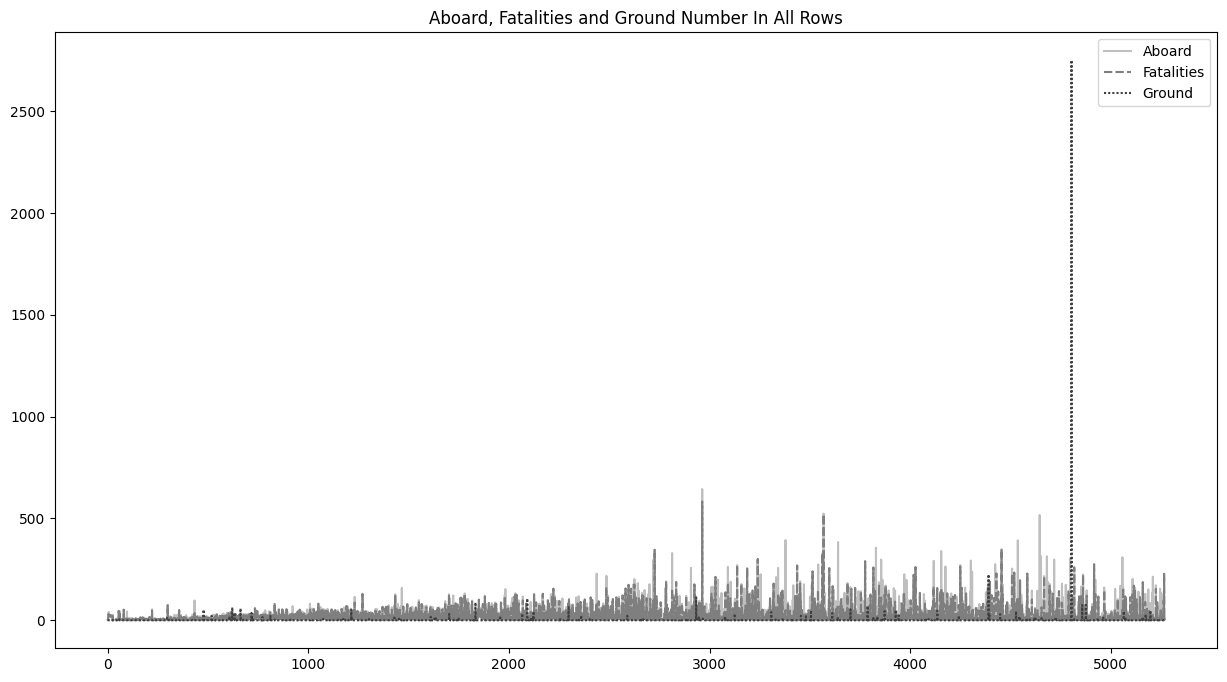

In [35]:
top10=df.iloc[:5269 , :]
top10u= top10.loc[:,['Aboard', 'Fatalities', 'Ground']]
print(top10u)
plt.figure(figsize=(15,8))
sns.lineplot(data=top10u,palette="binary")
plt.title('Aboard, Fatalities and Ground Number In All Rows')
plt.show

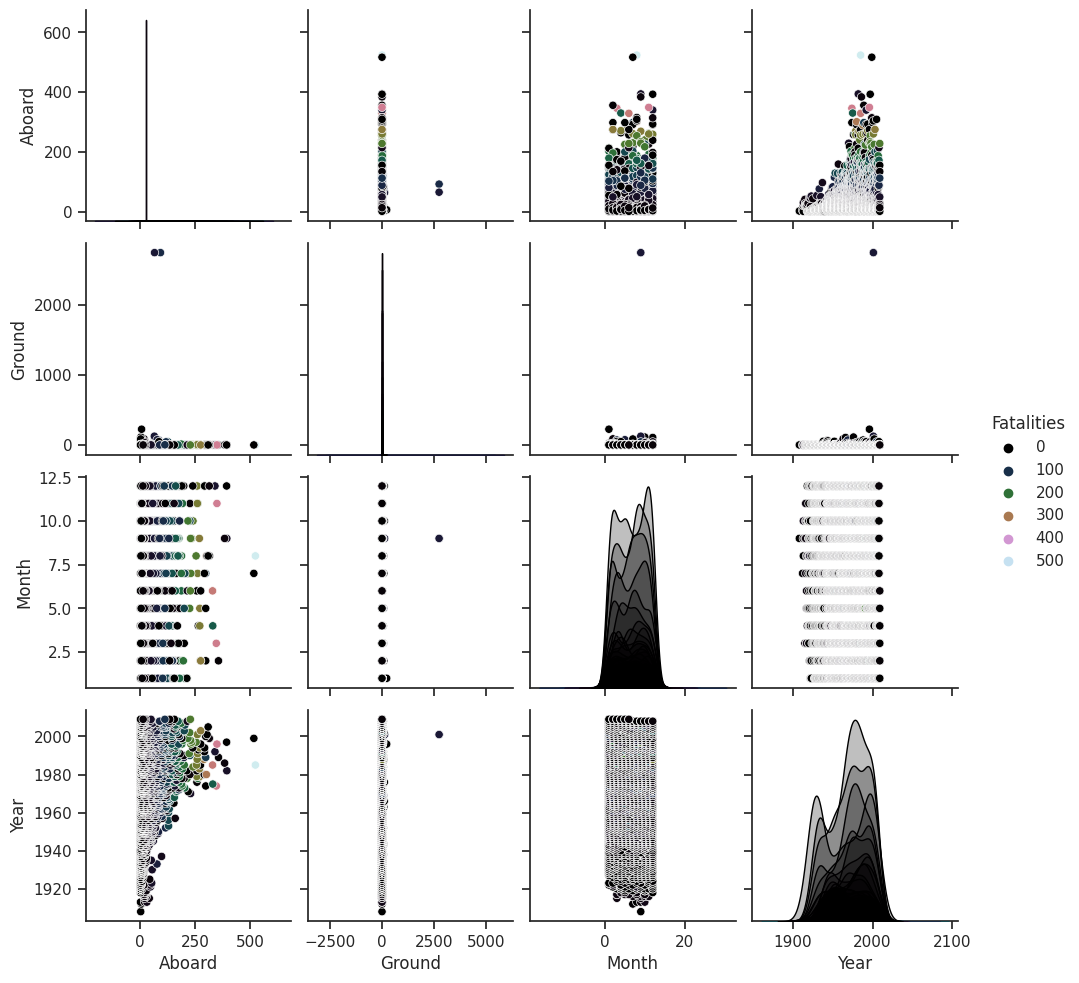

In [36]:
warnings.filterwarnings("ignore")
sns.set(style="ticks", color_codes=True)
sns.pairplot(data=df, diag_kind='kde',hue="Fatalities", palette="cubehelix")
plt.show()

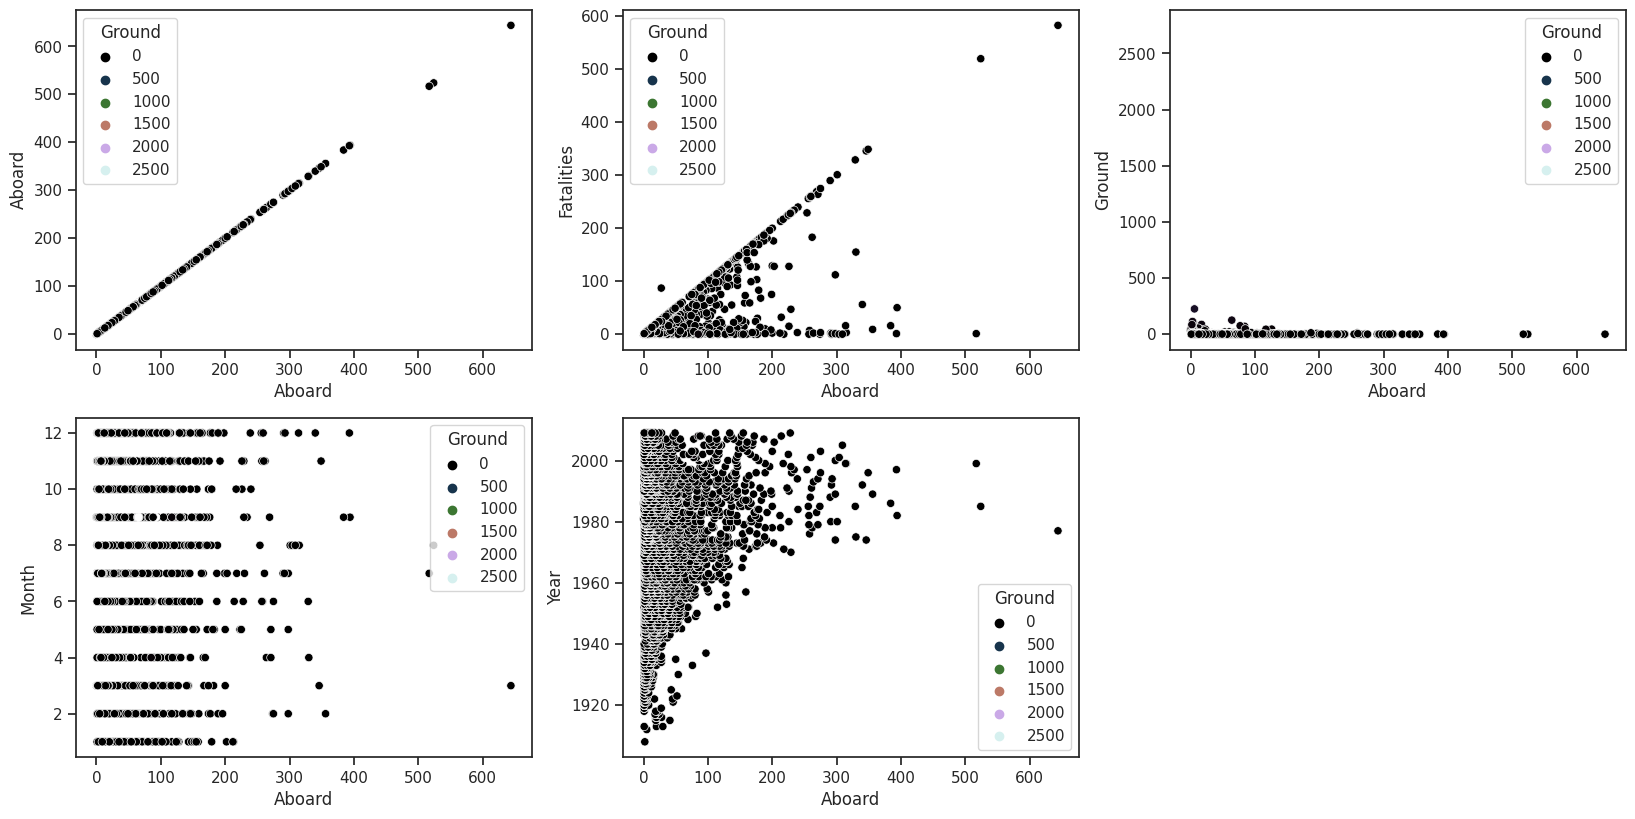

In [37]:
ff = ['Aboard', 'Fatalities', 'Ground','Month' ,'Year']
fig=plt.figure(figsize=(20,15))
for i,col in enumerate(ff):
    ax=fig.add_subplot(3,3,i+1)
    sns.scatterplot(x='Aboard',y=col,hue='Ground',data=df,palette="cubehelix")

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">
    
- There seems to be a positive connection between the number of individuals on an aircraft and the number of fatalities. It's expected since more people on board mean a higher potential for fatalities in case of an accident.

- The distribution of data points implies that for many incidents, the number of fatalities is relatively low compared to the number of people aboard. This suggests numerous accidents with a large number of survivors.

- There are incidents with remarkably high fatalities (over 500). These data points likely represent significant aviation disasters, standing out in the dataset.

- The plot shows outliers where the number of fatalities is notably lower than the number of people aboard, as well as outliers with a high number of fatalities for a relatively low number of people aboard.

- There's a dense cluster of points at the lower end of both axes, indicating that most aviation incidents involve fewer people and result in fewer fatalities.

- The number of people aboard seems to have a definite upper limit, likely corresponding to the maximum capacity of the largest commercial aircraft. This is seen in the horizontal line of points at the top of the scatter plot.

These scatter plots can assist aviation safety analysts in identifying accident severity patterns and investigating specific incidents that deviate from the general trend, such as those with exceptionally high fatalities relative to the number of people aboard.

In [38]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
color_scale = ["#495057", "#adb5bd", "#ced4da", "#343a40"]
fig = px.scatter_3d(df, x='Fatalities', y='Ground', z='Aboard', color='Year',color_continuous_scale=color_scale,  title='Distribution of Kills',template = 'plotly_white')
fig.update_traces(marker=dict(size=5))
fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">
    
- The graph reveals how the number of people on board, fatalities, and ground casualties in aviation incidents are connected in a three-dimensional way, allowing for looking at all three variables at the same time.

- The color spectrum represents different years, with cool colors for earlier years and warm colors for later years, giving a time context to the data points and helping to spot trends over time.

- Most incidents have fewer than 100 fatalities and a small number of people on board. Incidents with high fatalities or people on board, or with significant ground casualties, are less common.

- Some unusual data points, especially in ground casualties, suggest a few incidents with exceptionally high numbers of ground casualties compared to the typical range.

- In many incidents, there are fewer fatalities than people on board, possibly indicating successful emergency responses or non-fatal accidents.

- Most ground casualties are at the lower end of the scale, but a few incidents have very high ground casualties, hinting at major disasters affecting both passengers and those on the ground.

<Axes: >

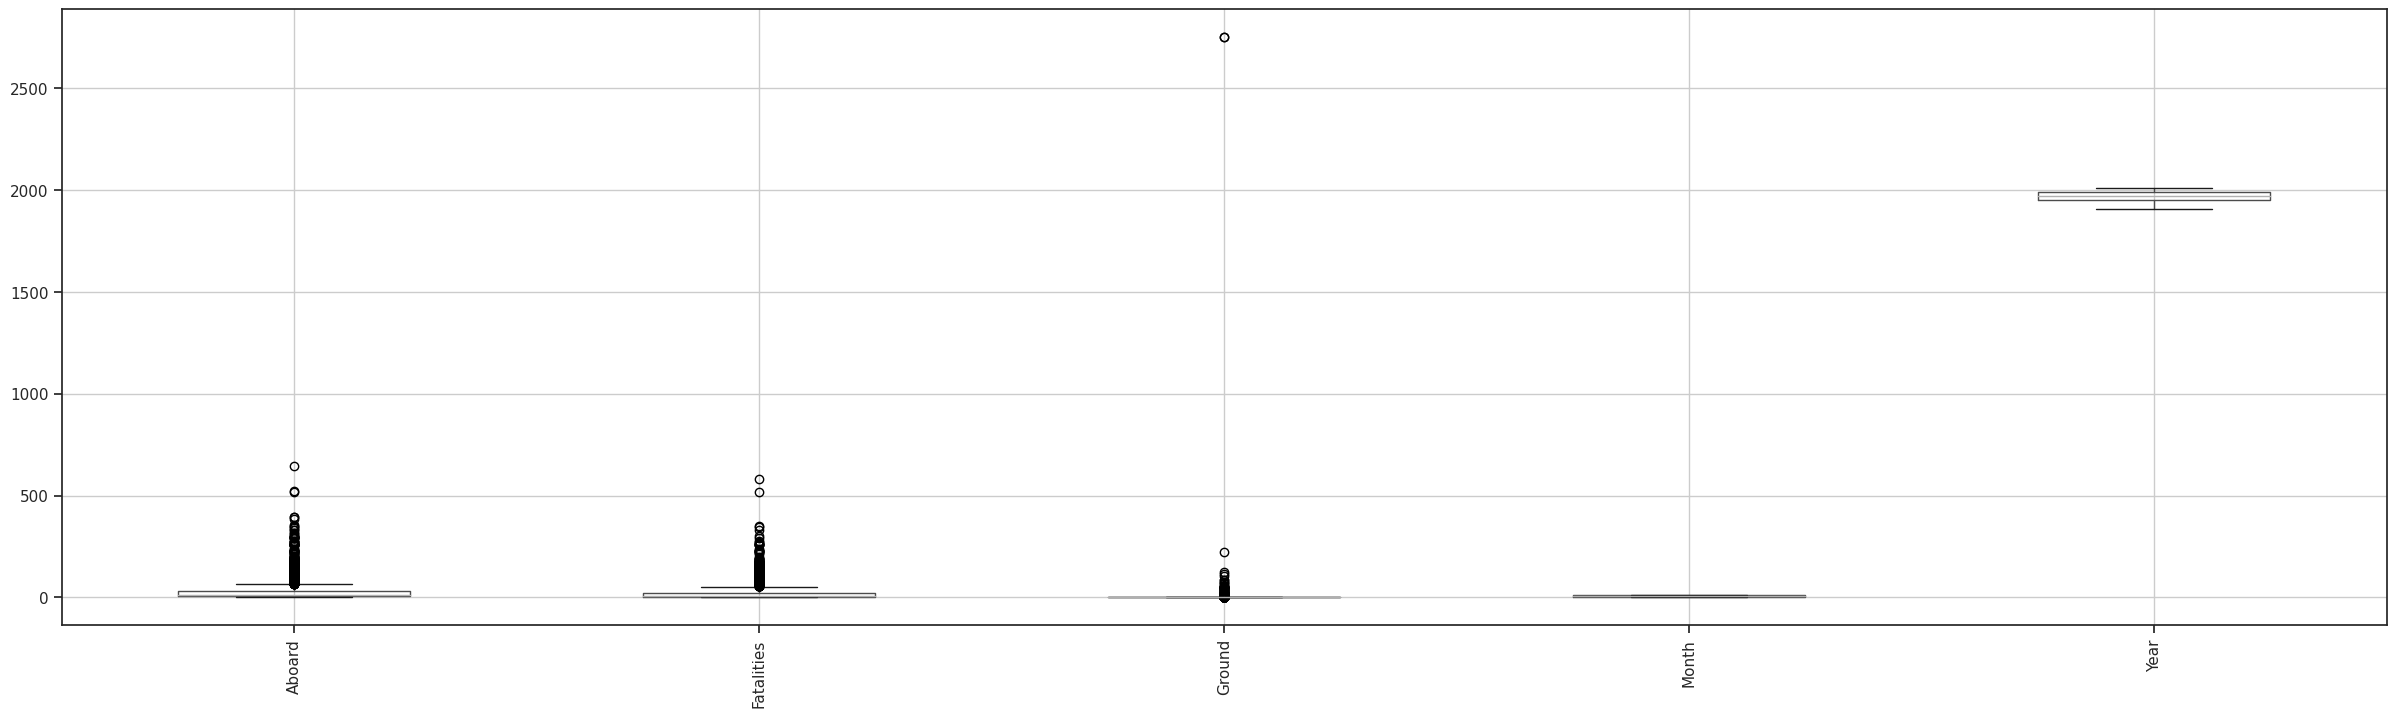

In [39]:
df.boxplot(rot=90 , figsize=(30,8))

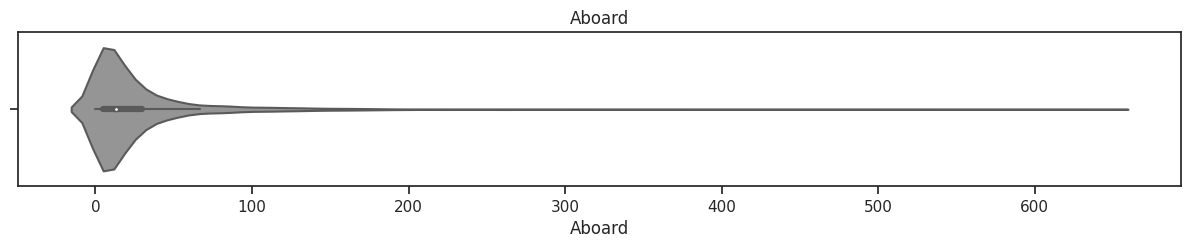

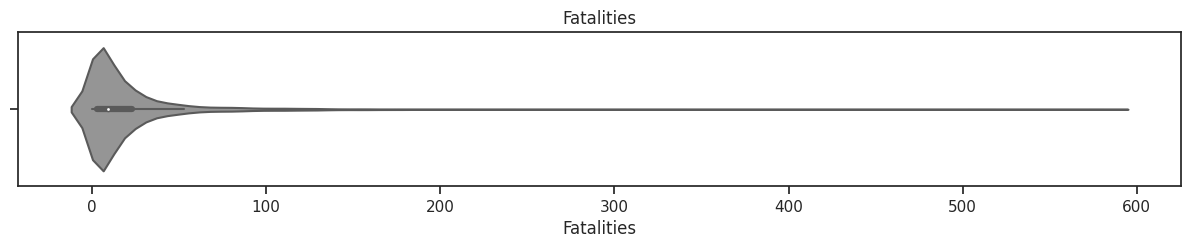

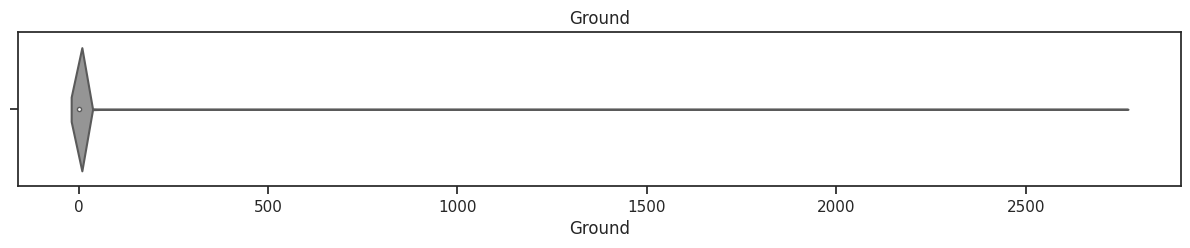

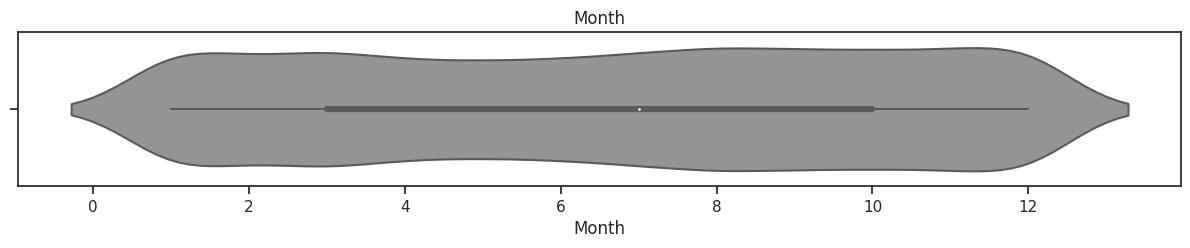

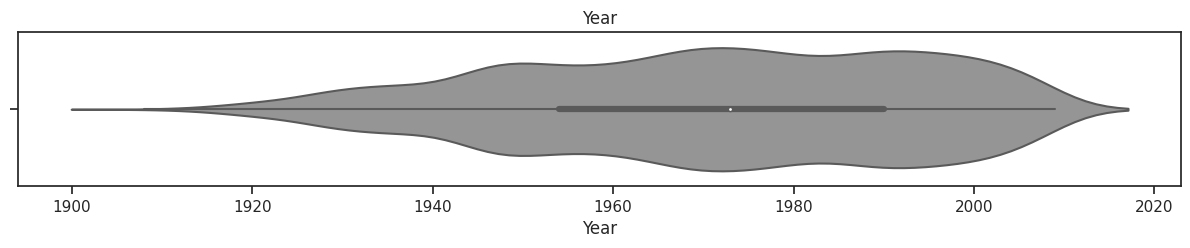

In [40]:
palette ="Greys"
for column in ff:
    plt.figure(figsize=(15,2))
    sns.violinplot(x=df[column], palette=palette)
    plt.title(column)
    plt.show()


Aboard Statistics:
count: 5268.00, mean: 27.55, std: 42.99, min: 0.00, 25%: 5.00, 50%: 13.00, 75%: 30.00, max: 644.00


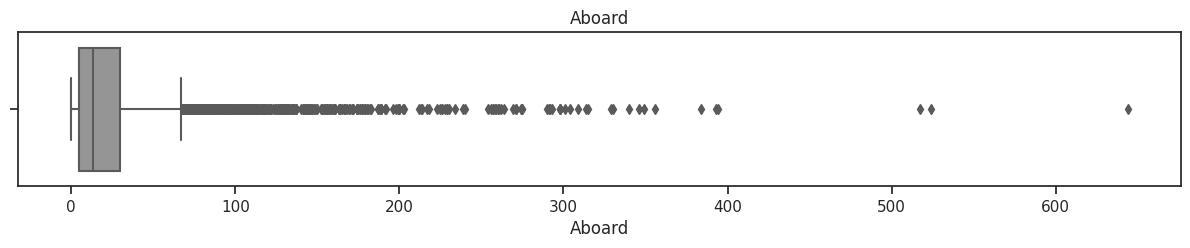


Fatalities Statistics:
count: 5268.00, mean: 20.07, std: 33.16, min: 0.00, 25%: 3.00, 50%: 9.00, 75%: 23.00, max: 583.00


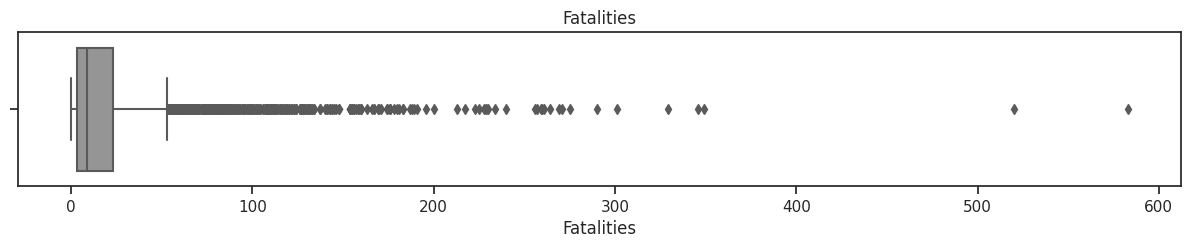


Ground Statistics:
count: 5268.00, mean: 1.61, std: 53.87, min: 0.00, 25%: 0.00, 50%: 0.00, 75%: 0.00, max: 2750.00


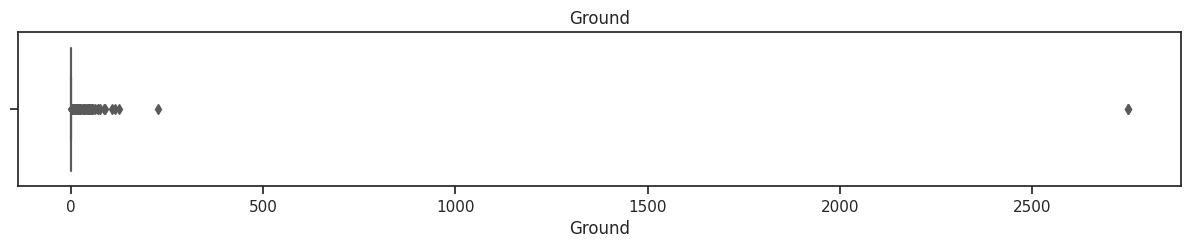


Month Statistics:
count: 5268.00, mean: 6.64, std: 3.55, min: 1.00, 25%: 3.00, 50%: 7.00, 75%: 10.00, max: 12.00


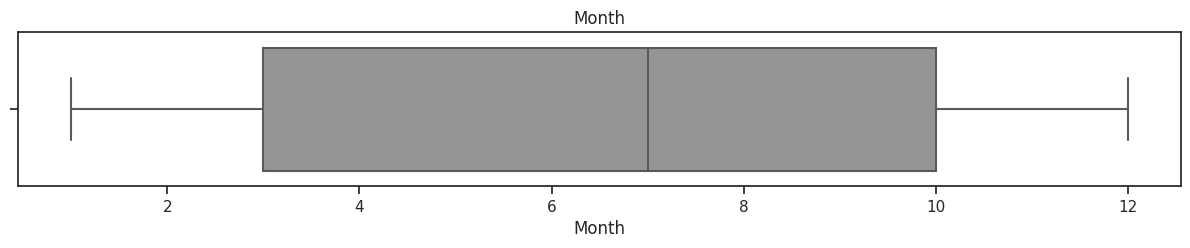


Year Statistics:
count: 5268.00, mean: 1971.30, std: 22.39, min: 1908.00, 25%: 1954.00, 50%: 1973.00, 75%: 1990.00, max: 2009.00


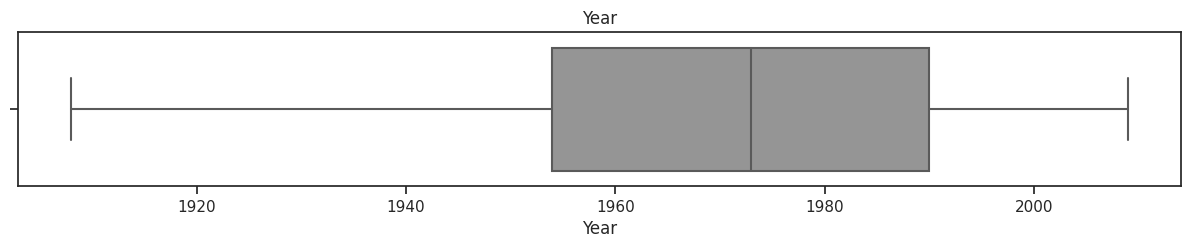

In [41]:
palette ="Greys"
for column in ff:
    plt.figure(figsize=(15,2))
    sns.boxplot(x=df[column], palette=palette)
    plt.title(column)
    stats = df[column].describe()
    stats_text = ", ".join([f"{key}: {value:.2f}" for key, value in stats.items()])
    print(f"\n{column} Statistics:\n{stats_text}")
    plt.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">
    
Each box plot displays important statistics like median, interquartile range, and outliers for different categories. The plot for Aboard suggests that fatalities per incident might be less than half the number of people aboard, but both Aboard and Fatalities show significant variability. Ground shows low or no ground fatalities in most incidents with a few high outlier incidents. There are notable extreme values in Fatalities and Aboard, indicating severe incidents. The scales of Fatalities and Aboard are different from Ground, with few high outliers. The highest outliers for Aboard and Fatalities skew the average. Overall, the box plot visually summarizes the data and accentuates the presence of outliers that may need further investigation.

In [42]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.line(data_frame=df, x='Date', y='Fatalities', title='Fatalities Based On Years', template='plotly_white')
fig.update_traces(line_color='#6c757d')
fig.show()

In [43]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.line(data_frame=df, x='Month', y='Fatalities', title='Fatalities Based On Month', template='plotly_white')
fig.update_traces(line_color='#6c757d')
fig.show()

In [44]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.histogram(df, x = 'Manufacture', template = 'plotly_white', title='Accidents by Manufacture',color_discrete_sequence=px.colors.sequential.gray)
fig.show()

In [45]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.histogram(df, x = 'Place', template = 'plotly_white', title='Accidents by Location',color_discrete_sequence=px.colors.sequential.gray)
fig.show()

In [46]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.bar(data_frame=df, x='Operator', title='Number of Incidents by Operator',  template='plotly_white',color_discrete_sequence=px.colors.sequential.gray)
fig.show()

In [47]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.histogram(df,x = 'Year', y = 'Ground', template = 'plotly_white', title='Ground Kills per year',color_discrete_sequence=px.colors.sequential.gray)
fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">
    
The graph displays total ground fatalities from aviation accidents per year. The x-axis represents the Year, and the y-axis shows the sum of ground fatalities each year. For most years, ground fatalities are low, usually fewer than 100 per year, as shown by small bars. However, there's a sharp increase in one year in the 2000s, where ground fatalities exceed 5,000. This stands out from other years and indicates a major and devastating event or series of events causing unusually high ground fatalities, possibly from a significant plane crash or multiple incidents in that year. The specific year of the spike isn't clear on the plot, but the dataset can be used to identify it and the incidents behind it. Excluding the spike, the data suggests that ground fatalities from aviation accidents are relatively rare compared to total individuals aboard and total passenger and crew fatalities. 

In [48]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.histogram(data_frame=df,x = 'Year' , y=['Fatalities','Aboard'],title='Kill Per Year',template='plotly_white',color_discrete_sequence=px.colors.sequential.ice)
fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">
    
The plotted data displays the total number of people aboard aircraft and the total number of fatalities due to aviation accidents, organized by year from the early 20th century to 2009. There is a general upward trend in both variables from the 1940s, likely linked to the growth of the commercial aviation industry and an increase in passenger flights.

Although aviation activity has increased overall, there are noticeable fluctuations from year to year, possibly reflecting the impact of significant accidents, changes in aviation safety regulations, technological advancements, or external factors such as wars or economic conditions.

Notably, in the last few years of the dataset (2005-2009), there appears to be a downward trend in both the number of people aboard and the number of fatalities, which could indicate improvements in aviation safety, changes in air traffic volume, or other factors not immediately discernible from the plot alone.

In [49]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig1 = px.histogram(data_frame=df, x='Fatalities', title='Distribution of Fatalities', template='plotly_white',color_discrete_sequence=px.colors.sequential.gray)
fig1.show()

In [50]:
fig = px.histogram(df, x="Fatalities", marginal="box", nbins=20, hover_data=df[['Location']])
fig.update_traces(
    boxpoints='all',
    boxmean='sd',
    marker=dict(color='#212529'),
    selector=dict(type='box'))
fig.update_traces(
    marker_color='#212529',
    selector=dict(type='histogram'))
fig.update_layout(
    xaxis_title="Fatalities",
    template='gridon',
    plot_bgcolor='rgba(0, 0, 0, 0)',
    paper_bgcolor='rgba(0, 0, 0, 0)',)
fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">
    
- The histogram indicates that there are more incidents with fewer fatalities and fewer incidents with a large number of fatalities, skewing to the right.

- The tallest bar on the left of the histogram suggests that most aviation incidents result in a low number of fatalities, possibly due to effective safety measures or less severe accidents.

- There is a long tail extending towards the right, indicating that while less frequent, there have been incidents with a very high number of fatalities, possibly major accidents.

- Incidents with fatalities over 100 are much rarer, with decreasing frequency as the number of fatalities increases, a typical pattern in such data distributions.

- There are only a few incidents with an extremely high number of fatalities further along the x-axis, potentially catastrophic events.

This distribution is consistent with many real-world scenarios where extreme values (in this case, high fatality incidents) are uncommon but significantly impactful. It emphasizes the importance of studying both common low-fatality incidents for safety improvements and rare high-fatality incidents to prevent disasters.

In [51]:
fig = px.histogram(df, x="Aboard", marginal="box", nbins=20, hover_data=df[['Location']])
fig.update_traces(
    boxpoints='all',
    boxmean='sd',
    marker=dict(color='#212529'),
    selector=dict(type='box'))
fig.update_traces(
    marker_color='#212529',
    selector=dict(type='histogram'))
fig.update_layout(
    xaxis_title="Aboard",
    template='gridon',
    plot_bgcolor='rgba(0, 0, 0, 0)',
    paper_bgcolor='rgba(0, 0, 0, 0)',)
fig.show()

In [52]:
fig = px.histogram(df, x="Ground", marginal="box", nbins=20, hover_data=df[['Location']])
fig.update_traces(
    boxpoints='all',
    boxmean='sd',
    marker=dict(color='#212529'),
    selector=dict(type='box'))
fig.update_traces(
    marker_color='#212529',
    selector=dict(type='histogram'))
fig.update_layout(
    xaxis_title="Ground",
    template='gridon',
    plot_bgcolor='rgba(0, 0, 0, 0)',
    paper_bgcolor='rgba(0, 0, 0, 0)',)
fig.show()

In [53]:
df2= df.set_index('Date')
df2.dropna(subset=['Fatalities', 'Aboard'], inplace=True)

In [54]:
rolling_mean = df2['Fatalities'].rolling(window=12).mean() 
rolling_std = df2['Fatalities'].rolling(window=12).std()  
decomposition = seasonal_decompose(df2['Fatalities'], model='additive', period=12) 

In [55]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = go.Figure()
fig.add_trace(go.Scatter(x=df2.index, y=df2['Fatalities'], mode='lines', name='Original',line=dict(color='#dee2e6')))
fig.add_trace(go.Scatter(x=df2.index, y=rolling_mean, mode='lines', name='Rolling Mean', line=dict(color='#212529')))
fig.add_trace(go.Scatter(x=df2.index, y=rolling_std, mode='lines', name='Rolling Std', line=dict(color='#adb5bd')))
fig.update_layout(title='Statistics of Fatalities', xaxis_title='Time', yaxis_title='Fatalities', template='plotly_white')
fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">


- Original Data: This likely represents the actual number of fatalities over time, plotted as a time series. The plot starts from around 1920 and continues to the 2000s. There are visible spikes at various points indicating years with higher numbers of fatalities.
- Rolling Mean: The red line smooths out fluctuations to show a longer-term trend in the data. This helps to identify whether there are upward or downward trends over time, aside from the short-term variations.
- Rolling Standard Deviation: This measures the variability of the data around the rolling mean. A higher rolling standard deviation indicates periods with greater fluctuations in the number of fatalities.
Key Observations:

- There's a general increase in the variability (standard deviation) starting around the 1940s, which could be due to the increase in air traffic post-World War II.
- The rolling mean appears relatively stable over time, with no drastic long-term upward or downward trends. This might suggest that while the number of flights and possibly the number of accidents has increased, advancements in safety have helped control the number of fatalities.
- The spikes in the original data could correspond to specific years with major accidents or disasters, contributing to a higher number of fatalities.
- The rolling standard deviation shows that the variability of the number of fatalities has increased over time, indicating that while the average number of fatalities may not have increased significantly, the range of outcomes in any given period has widened.
    
This type of analysis is useful for understanding trends and volatility in data over time, which is particularly relevant in fields like aviation where safety is of paramount importance and where it's useful to understand both the usual levels of risk and the potential for extreme events.

In [56]:
fig = make_subplots(rows=4, cols=1)
fig.add_trace(go.Scatter(x=df2.index, y=df2['Fatalities'], mode='lines', name='Original',line=dict(color='#e9ecef')), row=1, col=1)
fig.add_trace(go.Scatter(x=df2.index, y=decomposition.trend, mode='lines', name='Trend', line=dict(color='#dee2e6')), row=2, col=1)
fig.add_trace(go.Scatter(x=df2.index, y=decomposition.seasonal, mode='lines', name='Seasonal', line=dict(color='#adb5bd')), row=3, col=1)
fig.add_trace(go.Scatter(x=df2.index, y=decomposition.resid, mode='lines', name='Residual', line=dict(color='#6c757d')), row=4, col=1)
fig.update_layout(title='Seasonal Decomposition of Fatalities', xaxis_title='Time', yaxis_title='Component Value', template='plotly_white')
fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">

The plot breaks down aviation fatalities data into different components using seasonal decomposition:

- Original: Shows the actual fatalities data over time, with fluctuations representing yearly variability.

- Trend: Represents the long-term progression in the data, indicating a relatively flat trend, meaning no strong long-term increase or decrease in fatalities.

- Seasonal: Reflects periodic variations in the data within specific time frames. The plot suggests unclear seasonal patterns.

- Residual: Represents unexplained variability or irregularities after removing trend and seasonal components. Indicates significant unexplained variations in the data.

Overall, the analysis suggests that aviation fatalities have remained stable in the long term with no strong seasonal effects. However, there is considerable volatility as shown by the residuals, indicating unpredictable nature of accidents. This kind of analysis helps understand different influences on time series data such as trends, cyclicality, and irregular impacts.

In [57]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
fig = px.scatter(df,
                 x='Year',y='Fatalities',size='Aboard', color='Manufacture',  hover_name='Location', 
                 title='Year VS Fatalities VS People Aboard',
                 template='plotly_white',color_discrete_sequence=px.colors.sequential.Greys)  
fig.show()

In [58]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
z = df2[['Aboard', 'Fatalities', 'Ground','Year','Month']].corr()
fig = px.imshow(z, text_auto=True,aspect="auto", color_continuous_scale='Greys')
fig.show()

<div style="border-radius:10px; border:#6c757d solid; padding: 15px; background-color:#e9ecef
            ; font-size:110%; text-align:left">

This visual shows how different factors like 'Aboard', 'Fatalities', and 'Ground' are connected. The scale on the right shows the strength of the connection, from 0 (no connection) to 1 (strong connection).

- 'Aboard' and 'Fatalities' are moderately to highly related, indicating that incidents with more people aboard often lead to more fatalities, which makes sense. 'Ground' and 'Fatalities', as well as 'Ground' and 'Aboard', don't seem to have much of a connection, suggesting that the number of ground casualties in an accident isn't strongly linked to the number of people on the aircraft or the fatalities.

<div style="border-radius:10px; border:#6c757d solid; padding: 15px
            ; font-size:110%; text-align:left">

In conclusion, the analysis and exploratory data analysis (EDA) of airplane crashes have provided valuable insights into the factors contributing to such incidents. It is clear that continuous efforts in data collection, analysis, and the implementation of safety measures are crucial to mitigating the risks associated with air travel. By leveraging the findings from airplane crashs analysis, the aviation industry can work towards enhancing safety protocols, training, maintenance procedures, and technological advancements to ensure a safer future for air travel. The insights gained from this analysis will undoubtedly play a vital role in shaping the direction of aviation safety moving forward.